In [21]:
import xgboost

print(xgboost.__version__)

1.7.6


In [22]:
# 파이썬 래퍼 XGBoost 적용

import xgboost as xgb
from xgboost import plot_importance
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

dataset = load_breast_cancer()
X_features = dataset.data
y_label = dataset.target

In [23]:
df = pd.DataFrame(data = X_features, columns = dataset.feature_names)
df["target"] = y_label
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [24]:
print(dataset.target_names)
print(df["target"].value_counts)

['malignant' 'benign']
<bound method IndexOpsMixin.value_counts of 0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int32>


In [25]:
X_features = df.iloc[:, :-1]
y_label = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X_features, y_label,
                                                    test_size = 0.2, random_state = 156)

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size = 0.1, random_state = 156)

print(X_train.shape, X_test.shape)
print(X_tr.shape, X_val.shape)

(455, 30) (114, 30)
(409, 30) (46, 30)


In [26]:
dtr = xgb.DMatrix(data = X_tr, label = y_tr)
dval = xgb.DMatrix(data = X_val, label = y_val)
dtest = xgb.DMatrix(data = X_test, label = y_test)

In [27]:
params = {
    "max_depth": 3,
    "eta": 0.5,
    "objective": "binary:logistic",
    "eval_metric": "logloss"
}

num_rounds = 400

In [28]:
eval_list = [(dtr, "train"), (dval, "eva")]

xgb_model = xgb.train(params = params, dtrain = dtr, num_boost_round = num_rounds, early_stopping_rounds = 50, evals = eval_list)

[0]	train-logloss:0.35554	eva-logloss:0.45915
[1]	train-logloss:0.21879	eva-logloss:0.35750
[2]	train-logloss:0.14308	eva-logloss:0.30244
[3]	train-logloss:0.10147	eva-logloss:0.27501
[4]	train-logloss:0.07421	eva-logloss:0.26152
[5]	train-logloss:0.05751	eva-logloss:0.26290
[6]	train-logloss:0.04717	eva-logloss:0.27088
[7]	train-logloss:0.03729	eva-logloss:0.27125
[8]	train-logloss:0.03133	eva-logloss:0.29146
[9]	train-logloss:0.02748	eva-logloss:0.29061
[10]	train-logloss:0.02375	eva-logloss:0.29161
[11]	train-logloss:0.02058	eva-logloss:0.29964
[12]	train-logloss:0.01792	eva-logloss:0.27732
[13]	train-logloss:0.01636	eva-logloss:0.27806
[14]	train-logloss:0.01472	eva-logloss:0.27727
[15]	train-logloss:0.01350	eva-logloss:0.26936
[16]	train-logloss:0.01233	eva-logloss:0.26380
[17]	train-logloss:0.01144	eva-logloss:0.26799
[18]	train-logloss:0.01114	eva-logloss:0.26521
[19]	train-logloss:0.01026	eva-logloss:0.26545
[20]	train-logloss:0.00966	eva-logloss:0.25249
[21]	train-logloss:0.00

In [29]:
pred_probs = xgb_model.predict(dtest)
print(np.round(pred_probs[:10], 3))

preds = [1 if x > 0.5 else 0 for x in pred_probs]
print(preds[:10])

[0.982 0.005 0.6   0.008 0.989 1.    1.    1.    0.999 0.   ]
[1, 0, 1, 0, 1, 1, 1, 1, 1, 0]


In [30]:
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score

def get_clf_eval(y_test, pred = None, pred_proba = None):
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)
    print("오차행렬")
    print(confusion)
    print("정확도: ", accuracy)
    print("정밀도: ", precision)
    print("재현율: ", recall)
    print("f1: ", f1)
    print("roc_auc: ", roc_auc)

In [31]:
get_clf_eval(y_test, preds, pred_probs)

오차행렬
[[34  3]
 [ 2 75]]
정확도:  0.956140350877193
정밀도:  0.9615384615384616
재현율:  0.974025974025974
f1:  0.967741935483871
roc_auc:  0.992979992979993


<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

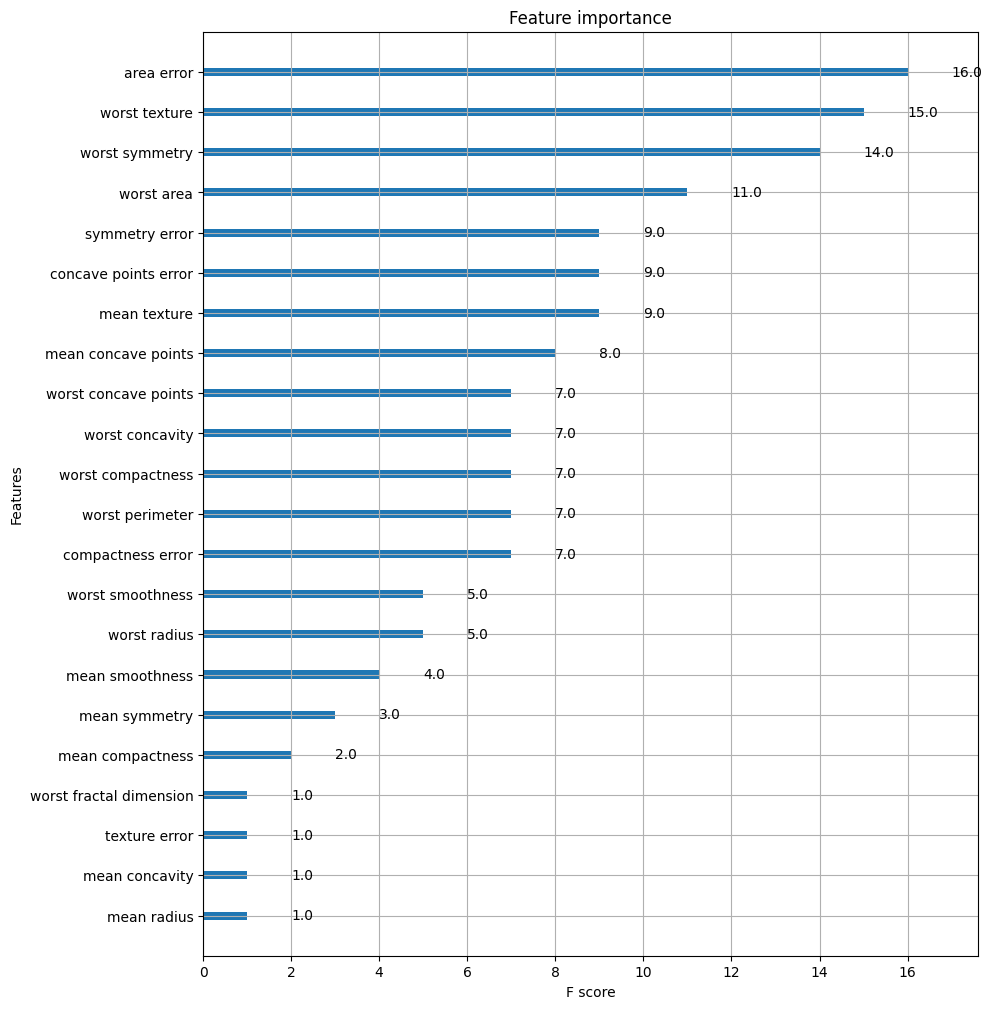

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize = (10, 12))
plot_importance(xgb_model, ax = ax)

In [33]:
# 사이킷런 래퍼로 XGBoost 클래스 임포트

from xgboost import XGBClassifier

xgb_wrapper = XGBClassifier(n_estimators = 400, learning_rage = 0.1,
                            max_depth = 3)
xgb_wrapper.fit(X_train, y_train)
w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

[10:28:35] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "learning_rage" } are not used.



In [34]:
get_clf_eval(y_test, w_preds, w_pred_proba)

오차행렬
[[35  2]
 [ 1 76]]
정확도:  0.9736842105263158
정밀도:  0.9743589743589743
재현율:  0.987012987012987
f1:  0.9806451612903225
roc_auc:  0.9961389961389961


In [35]:
xgb_wrapper = XGBClassifier(n_estimators = 400, learning_rate = 0.1,
                            max_depth = 3, early_stopping_rounds = 100,
                            eval_metric = "logloss")
evals = [(X_test, y_test)]
xgb_wrapper.fit(X_train, y_train, eval_set = evals, verbose = True)

ws100_pred = xgb_wrapper.predict(X_test)
ws100_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

[0]	validation_0-logloss:0.61352
[1]	validation_0-logloss:0.54784
[2]	validation_0-logloss:0.49425
[3]	validation_0-logloss:0.44799
[4]	validation_0-logloss:0.40911
[5]	validation_0-logloss:0.37498
[6]	validation_0-logloss:0.34571
[7]	validation_0-logloss:0.32053
[8]	validation_0-logloss:0.29721
[9]	validation_0-logloss:0.27799
[10]	validation_0-logloss:0.26030
[11]	validation_0-logloss:0.24604
[12]	validation_0-logloss:0.23156
[13]	validation_0-logloss:0.22005
[14]	validation_0-logloss:0.20857
[15]	validation_0-logloss:0.19999
[16]	validation_0-logloss:0.19012
[17]	validation_0-logloss:0.18182
[18]	validation_0-logloss:0.17473
[19]	validation_0-logloss:0.16766
[20]	validation_0-logloss:0.15820
[21]	validation_0-logloss:0.15472
[22]	validation_0-logloss:0.14895
[23]	validation_0-logloss:0.14331
[24]	validation_0-logloss:0.13634
[25]	validation_0-logloss:0.13278
[26]	validation_0-logloss:0.12791
[27]	validation_0-logloss:0.12526
[28]	validation_0-logloss:0.11998
[29]	validation_0-loglos

In [36]:
get_clf_eval(y_test, ws100_pred, ws100_pred_proba)

오차행렬
[[34  3]
 [ 1 76]]
정확도:  0.9649122807017544
정밀도:  0.9620253164556962
재현율:  0.987012987012987
f1:  0.9743589743589742
roc_auc:  0.9954369954369954


In [37]:
xgb_wrapper = XGBClassifier(n_estimators = 400, learning_rate = 0.1,
                            max_depth = 3, early_stopping_rounds = 10,
                            eval_metric = "logloss")
evals = [(X_test, y_test)]
xgb_wrapper.fit(X_train, y_train, eval_set = evals, verbose = True)

ws10_pred = xgb_wrapper.predict(X_test)
ws10_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

get_clf_eval(y_test, ws10_pred, ws10_pred_proba)

[0]	validation_0-logloss:0.61352
[1]	validation_0-logloss:0.54784
[2]	validation_0-logloss:0.49425
[3]	validation_0-logloss:0.44799
[4]	validation_0-logloss:0.40911
[5]	validation_0-logloss:0.37498
[6]	validation_0-logloss:0.34571
[7]	validation_0-logloss:0.32053
[8]	validation_0-logloss:0.29721
[9]	validation_0-logloss:0.27799
[10]	validation_0-logloss:0.26030
[11]	validation_0-logloss:0.24604
[12]	validation_0-logloss:0.23156
[13]	validation_0-logloss:0.22005
[14]	validation_0-logloss:0.20857
[15]	validation_0-logloss:0.19999
[16]	validation_0-logloss:0.19012
[17]	validation_0-logloss:0.18182
[18]	validation_0-logloss:0.17473
[19]	validation_0-logloss:0.16766
[20]	validation_0-logloss:0.15820
[21]	validation_0-logloss:0.15472
[22]	validation_0-logloss:0.14895
[23]	validation_0-logloss:0.14331
[24]	validation_0-logloss:0.13634
[25]	validation_0-logloss:0.13278
[26]	validation_0-logloss:0.12791
[27]	validation_0-logloss:0.12526
[28]	validation_0-logloss:0.11998
[29]	validation_0-loglos

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

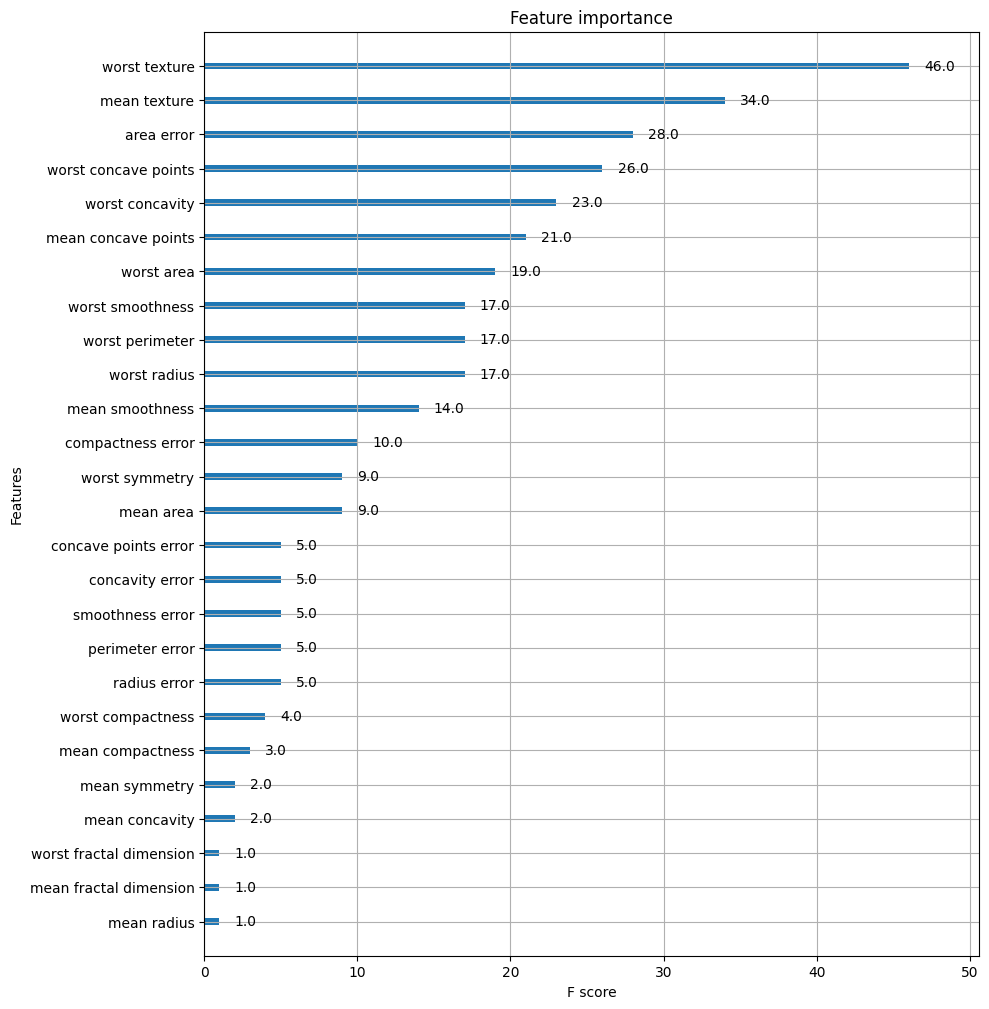

In [38]:
fig, ax = plt.subplots(figsize = (10, 12))
plot_importance(xgb_wrapper, ax = ax)